# Image Spatter — adım adım ELA

**Burada ne yapıyoruz?** Bir fotoğrafa küçük bir parça ekleyip JPEG sıkıştırma farklarında bu parçanın nasıl göründüğüne bakıyoruz.

ELA'nın fikri şu: **Görüntüyü tekrar JPEG olarak kaydet. Önceki ve sonraki piksel değerlerini karşılaştır.**

Hücreleri yukarıdan aşağıya çalıştır. İlk örneği fonksiyon kullanmadan yapacağız; sonra aynı işlemi tekrar kullanmak için bir fonksiyona koyacağız.

Parlak bir ELA bölgesi, o bölgede daha büyük sıkıştırma farkı olduğunu gösterir. Tek başına “burası sahte” anlamına gelmez.


## 1. Kütüphaneleri aç

- `cv2`: görüntü okuma, kaydetme ve fark alma.
- `numpy`: görüntüyü oluşturan sayı dizileriyle çalışma.
- `matplotlib`: görüntüleri ekranda gösterme.
- `Path`: dosya ve klasör yollarını yazma.
- `perf_counter`: işlemin ne kadar sürdüğünü ölçme.


In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter


## 2. Görüntüyü oku

Notebook'u **Image_Processing_Project klasöründe** aç.

`data` içinde örnek görüntümüz var. Ürettiğimiz dosyalar `outputs` içine gidecek.
`exist_ok=True`, klasör zaten varsa hata verme demek.

`str(...)`, dosya yolunu OpenCV için yazıya çevirir.


In [25]:
data_dir = Path("data")
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

source_img = cv2.imread(str(data_dir / "astronaut.png"))

if source_img is None:
    raise FileNotFoundError("data/astronaut.png bulunamadı. Notebook'u proje klasöründe aç.")

print("Görüntü boyutu:", source_img.shape)


Görüntü boyutu: (512, 512, 3)


`shape` sonucu `(512, 512, 3)`: 512 satır, 512 sütun ve 3 renk kanalı.

OpenCV renkleri **BGR** sırasında okur. Matplotlib **RGB** bekler. Bu yüzden ekranda gösterirken `cv2.cvtColor` kullanacağız.


## 3. Kontrollü bir düzenleme yap

### 3.1. JPEG bir arka plan hazırla

PNG kaynağımızı önce JPEG kalite **75** ile kaydedip tekrar okuyoruz.
JPEG bazı bilgileri kaybettiği için okuduğumuz piksel değerleri kaynaktan biraz farklı olacak.

Bu adımı, arka planla birazdan ekleyeceğimiz parçanın sıkıştırma geçmişleri farklı olsun diye yapıyoruz.


In [26]:
base_path = output_dir / "base_q75.jpg"

cv2.imwrite(str(base_path), source_img, [cv2.IMWRITE_JPEG_QUALITY, 75])
base_img = cv2.imread(str(base_path))


### 3.2. Bir parçayı başka yere yapıştır

Görüntüden parça seçerken yazım sırası:

`görüntü[başlangıç_satırı:bitiş_satırı, başlangıç_sütunu:bitiş_sütunu]`

Aşağıdaki ilk aralık armayı seçer: **340–419. satırlar, 130–209. sütunlar**.
Her iki aralık da 80 piksel uzunluğunda; yani parça **80 × 80**.

`.copy()` kullanarak arka planın ayrı bir kopyasını düzenliyoruz.


In [27]:
patch = source_img[340:420, 130:210].copy()

edited_img = base_img.copy()
edited_img[40:120, 390:470] = patch


### 3.3. İki görüntüyü de aynı son kaliteyle kaydet

**Kontrol:** Parça eklenmemiş görüntü.  
**Düzenlenmiş:** Sağ üstüne arma eklediğimiz görüntü.

İkisini de kalite **95** ile kaydediyoruz. Böylece son kaydetme ayarları aynı oluyor.
ELA hesabında bu dosyalardan geri okuduğumuz görüntüleri kullanacağız.


In [28]:
original_path = output_dir / "control.jpg"
edited_path = output_dir / "edited.jpg"

cv2.imwrite(str(original_path), base_img, [cv2.IMWRITE_JPEG_QUALITY, 95])
cv2.imwrite(str(edited_path), edited_img, [cv2.IMWRITE_JPEG_QUALITY, 95])

original_img = cv2.imread(str(original_path))
edited_img = cv2.imread(str(edited_path))


### 3.4. Düzenlediğimiz yeri göster

Bir **maske**, hangi piksellerle ilgilendiğimizi gösteren ayrı bir görüntüdür.

Burada siyah **0**, beyaz **255**. Sadece parçayı eklediğimiz alanı beyaz yapıyoruz.
Bu alanı algoritma bulmadı; parçayı biz eklediğimiz için yerini biliyoruz.

`shape[:2]` sadece satır ve sütun sayısını alır. `zeros` bu boyutta sıfırlardan oluşan bir görüntü oluşturur. `uint8`, 0–255 arasındaki tam sayıları tutan veri tipidir.


In [29]:
known_mask = np.zeros(edited_img.shape[:2], dtype=np.uint8)
known_mask[40:120, 390:470] = 255

cv2.imwrite(str(output_dir / "known_mask.png"), known_mask)


True

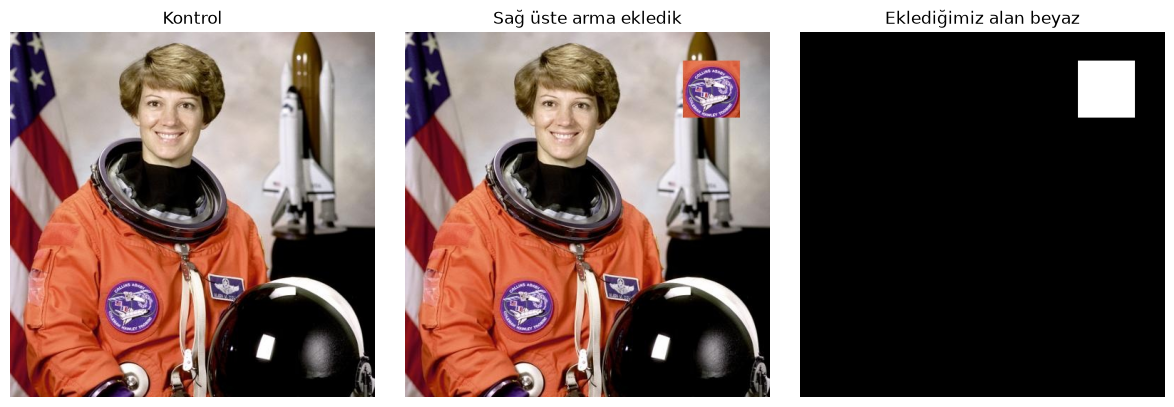

In [30]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Kontrol")
plt.axis(False)

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.title("Sağ üste arma ekledik")
plt.axis(False)

plt.subplot(1, 3, 3)
plt.imshow(known_mask, cmap="gray", vmin=0, vmax=255)
plt.title("Eklediğimiz alan beyaz")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "controlled_edit.png")
plt.show()


## 4. ELA hesabını adım adım yap

### 4.1. Düzenlenmiş görüntüyü tekrar JPEG olarak kaydet

Bu kez kalite **90** kullanıyoruz.
`recompressed_img`, bu yeni JPEG dosyasından geri okuduğumuz görüntü.

Henüz fark hesabı yapmadık; sadece karşılaştıracağımız ikinci görüntüyü hazırladık.


In [31]:
jpeg_quality = 90
recompressed_path = output_dir / "recompressed.jpg"

cv2.imwrite(str(recompressed_path), edited_img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality])
recompressed_img = cv2.imread(str(recompressed_path))


### 4.2. İki görüntünün farkını al

`edited_img`: yeniden kaydetmeden önceki görüntü.  
`recompressed_img`: yeniden kaydettikten sonraki görüntü.

`absdiff`, aynı konumdaki piksel değerlerinin **mutlak farkını** alır.

Örnek: 120 ile 115 arasındaki fark **5**. Aynı kalan bir değerin farkı **0**.
Doğrudan `uint8` çıkarma işlemi yerine bunu kullanıyoruz; negatif farklarda taşma olmasını önlüyor.


In [32]:
difference_img = cv2.absdiff(edited_img, recompressed_img)

print("Fark görüntüsünün boyutu:", difference_img.shape)


Fark görüntüsünün boyutu: (512, 512, 3)


### 4.3. Üç renk farkını tek sayıya indir

Her pikselde B, G ve R için üç ayrı fark var.
`mean(axis=2)`, **renk kanallarının ortalamasını** alır.

Örnek: bir pikselde farklar `[3, 6, 9]` ise sonuç `(3 + 6 + 9) / 3 = 6`.

Böylece 3 kanallı fark görüntüsü, tek bir **ELA haritasına** dönüşür.


In [33]:
edited_ela = difference_img.mean(axis=2)

print("ELA haritasının boyutu:", edited_ela.shape)
print("Görüntünün ortalama farkı:", round(edited_ela.mean(), 3))


ELA haritasının boyutu: (512, 512)
Görüntünün ortalama farkı: 0.801


### 4.4. Aynı işlemi kontrol görüntüsüne de uygula

Yine aynı üç adım: **kaydet → oku → farkı hesapla**.
Kaliteyi değiştirmiyoruz; iki görüntüyü aynı ayarla karşılaştıracağız.


In [34]:
cv2.imwrite(str(recompressed_path), original_img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality])
recompressed_original = cv2.imread(str(recompressed_path))

original_difference = cv2.absdiff(original_img, recompressed_original)
original_ela = original_difference.mean(axis=2)


## 5. Sonuçları yan yana göster

`plt.subplot(2, 2, 1)`: **2 satır, 2 sütun**, birinci kutuya çiz.

ELA haritalarında aynı renk ölçeğini kullanıyoruz: **0–20**.
Koyu renk küçük farkı, açık renk büyük farkı gösterir.
20 üzerindeki değerler de en açık renkte görünür; bu sınır sadece çizim içindir.


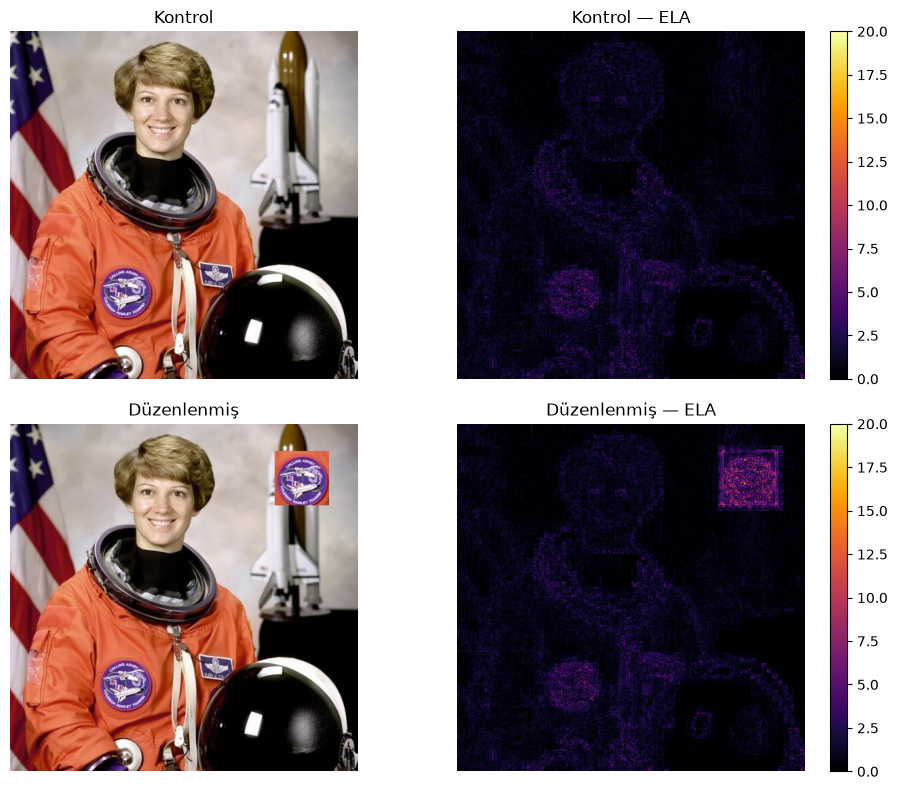

In [35]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Kontrol")
plt.axis(False)

plt.subplot(2, 2, 2)
plt.imshow(original_ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar()
plt.title("Kontrol — ELA")
plt.axis(False)

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.title("Düzenlenmiş")
plt.axis(False)

plt.subplot(2, 2, 4)
plt.imshow(edited_ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar()
plt.title("Düzenlenmiş — ELA")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "ela_comparison.png")
plt.show()


### ELA'yı görüntünün üstüne koy

İlk `imshow` fotoğrafı çizer. İkinci `imshow`, ELA haritasını onun üstüne çizer.
`alpha=0.5`, üstteki haritanın yarı saydam görünmesini sağlar.


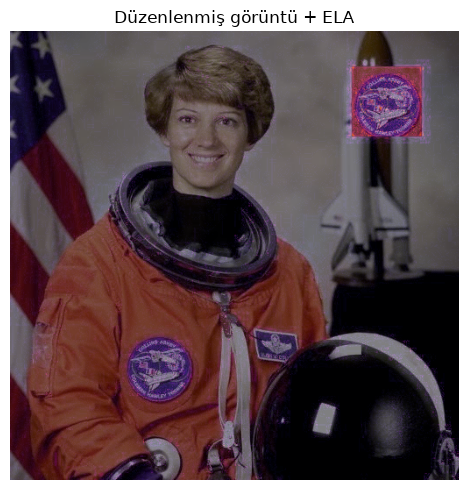

In [36]:
plt.figure(figsize=(5, 5))

plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.imshow(edited_ela, cmap="inferno", vmin=0, vmax=20, alpha=0.5)
plt.title("Düzenlenmiş görüntü + ELA")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "ela_overlay.png")
plt.show()


### Eklediğimiz alandaki farkı sayıyla karşılaştır

İki haritada da **aynı koordinatları** seçip ortalama farkı hesaplıyoruz.

Buradaki sayılar piksel farklarının ortalamasıdır. **Yüzde veya sahte olma olasılığı değildir.**
JPEG, parçanın sınırının çevresindeki pikselleri de etkileyebilir.

`round(değer, 3)`, ekrana yazılan sayıyı üç ondalık basamağa yuvarlar.


In [37]:
original_region = original_ela[40:120, 390:470]
edited_region = edited_ela[40:120, 390:470]

print("Kontrolde bu alanın ortalama farkı:", round(original_region.mean(), 3))
print("Düzenlemeden sonra ortalama fark:", round(edited_region.mean(), 3))


Kontrolde bu alanın ortalama farkı: 0.556
Düzenlemeden sonra ortalama fark: 4.475


## 6. Aynı hesabı tekrar kullan: fonksiyon

Buraya kadar ELA'yı tek tek yaptık. Şimdi **aynı satırları** bir fonksiyonun içine koyuyoruz.

`calculate_ela(img, quality)`:
- `img`: inceleyeceğimiz görüntü.
- `quality`: yeniden kaydederken kullanılacak JPEG kalitesi.
- `return`: hesaplanan ELA haritasını bize geri verir.

`recompressed.jpg` tekrar kullanılan bir çalışma dosyasıdır; her çağrıda üzerine yazılır.


In [38]:
def calculate_ela(img, quality):
    if not isinstance(quality, int) or not 1 <= quality <= 100:
        raise ValueError("JPEG kalitesi 1 ile 100 arasında bir tam sayı olmalı.")

    saved = cv2.imwrite(str(recompressed_path), img, [cv2.IMWRITE_JPEG_QUALITY, quality])
    if not saved:
        raise OSError("JPEG dosyası kaydedilemedi.")

    recompressed_img = cv2.imread(str(recompressed_path))
    difference_img = cv2.absdiff(img, recompressed_img)
    ela_map = difference_img.mean(axis=2)

    return ela_map


### Süreyi ölç

Başlangıç ve bitiş saatinin farkını alıyoruz.
Sonuç saniye cinsinden geldiği için **1000** ile çarparak milisaniyeye çeviriyoruz.

Bu sürüm JPEG'i diske yazıp okuduğu için ölçülen süreye **dosya yazma ve okuma da dahildir**.


In [39]:
start_time = perf_counter()

test_ela = calculate_ela(edited_img, 90)

elapsed_ms = (perf_counter() - start_time) * 1000
print("ELA işlem süresi (ms):", round(elapsed_ms, 2))


ELA işlem süresi (ms): 14.66


## 7. Kaliteyi değiştirip dene

Şimdi aynı fonksiyonu **80, 90 ve 95** kalite değerleriyle çağırıyoruz.

`for quality in qualities`: listedeki her kalite için aşağıdaki işlemleri sırayla yap.  
`append`: sonucu listenin sonuna ekle.

Her seferinde iki görüntüyü de aynı kalitede analiz ediyoruz.


In [40]:
qualities = [80, 90, 95]
original_maps = []
edited_maps = []
quality_results = []

for quality in qualities:
    start_time = perf_counter()
    original_map = calculate_ela(original_img, quality)
    original_time = (perf_counter() - start_time) * 1000

    start_time = perf_counter()
    edited_map = calculate_ela(edited_img, quality)
    edited_time = (perf_counter() - start_time) * 1000

    original_mean = original_map[40:120, 390:470].mean()
    edited_mean = edited_map[40:120, 390:470].mean()

    original_maps.append(original_map)
    edited_maps.append(edited_map)
    quality_results.append([quality, original_mean, edited_mean, original_time, edited_time])

    print("JPEG kalitesi:", quality)
    print("  Kontrol alanındaki ortalama fark:", round(original_mean, 3))
    print("  Eklenen alandaki ortalama fark:", round(edited_mean, 3))


JPEG kalitesi: 80
  Kontrol alanındaki ortalama fark: 0.844
  Eklenen alandaki ortalama fark: 6.625
JPEG kalitesi: 90
  Kontrol alanındaki ortalama fark: 0.556
  Eklenen alandaki ortalama fark: 4.475
JPEG kalitesi: 95
  Kontrol alanındaki ortalama fark: 0.273
  Eklenen alandaki ortalama fark: 2.046


### Üç kaliteyi aynı grafikte göster

Döngüde `i` sırasıyla **0, 1, 2** olur.

Üst sıradaki kutular **1, 2, 3**: kontrol görüntüsünün ELA haritaları.  
Alt sıradaki kutular **4, 5, 6**: düzenlenmiş görüntünün ELA haritaları.

Bu yüzden üst sıra için `i + 1`, alt sıra için `i + 4` yazıyoruz.


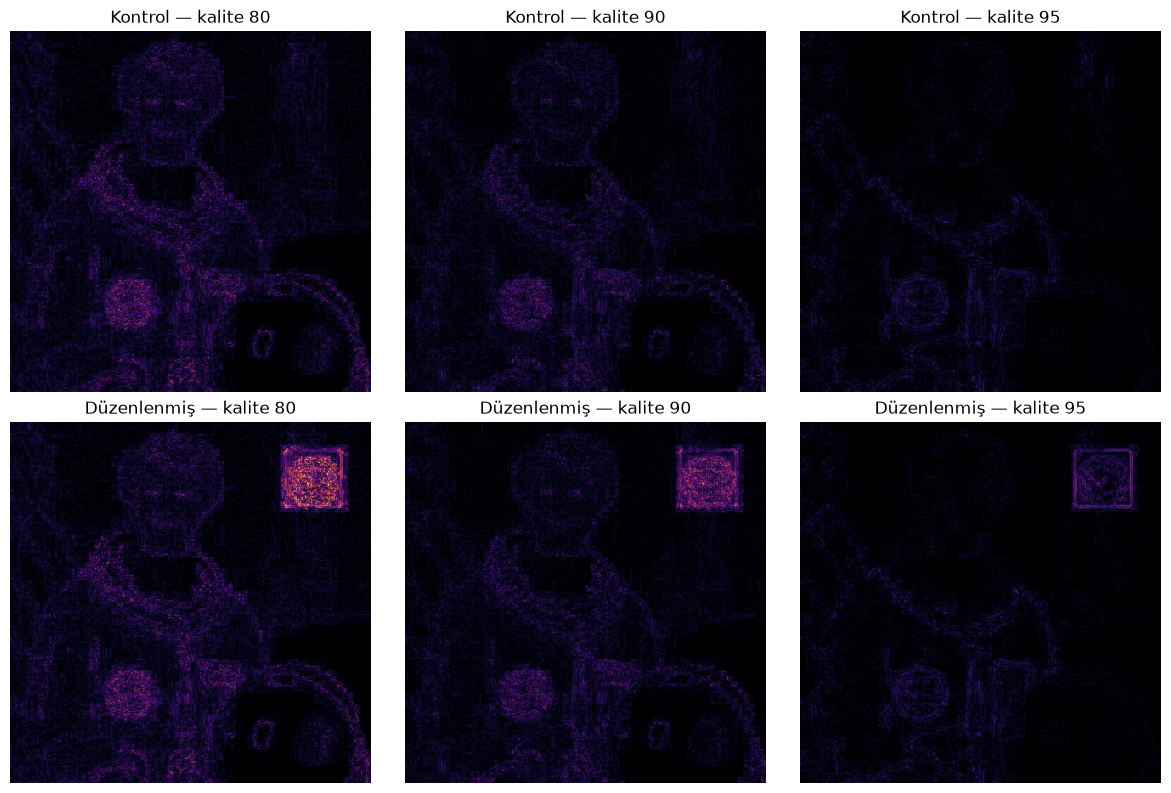

In [41]:
plt.figure(figsize=(12, 8))

for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(original_maps[i], cmap="inferno", vmin=0, vmax=20)
    plt.title(f"Kontrol — kalite {qualities[i]}")
    plt.axis(False)

    plt.subplot(2, 3, i + 4)
    plt.imshow(edited_maps[i], cmap="inferno", vmin=0, vmax=20)
    plt.title(f"Düzenlenmiş — kalite {qualities[i]}")
    plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "quality_comparison.png")
plt.show()


### Ölçümleri dosyaya kaydet

`quality_results` listesindeki her satırda sırasıyla şunlar var:

**JPEG kalitesi, kontrol bölgesinin ortalama farkı, düzenlenmiş bölgenin ortalama farkı, kontrol süresi, düzenlenmiş görüntünün süresi.**

CSV, bu sayıları Excel gibi bir programda da açabilmemizi sağlar.


In [42]:
np.savetxt(
    output_dir / "quality_comparison.csv",
    quality_results,
    delimiter=",",
    header="jpeg_quality,control_region_mean,edited_region_mean,control_time_ms,edited_time_ms",
    comments="",
    fmt="%.3f"
)


## Ne gördük?

- JPEG'i tekrar kaydetmek piksel değerlerinde fark oluşturuyor; ELA bu farkı gösteriyor.
- Bu deneyde farklı sıkıştırma geçmişi olan bir parça ekledik. Bu, ELA'yı göstermek için seçilmiş bir örnek.
- Kontrol görüntüsündeki arma, kenarlar ve dokular da fark üretebiliyor.
- Kullanılan JPEG kalitesi sonucu değiştiriyor. Her düzenleme görünür olmak zorunda değil.
- Tek örnekten genel tespit başarısı veya “gerçek / sahte” kararı çıkaramayız.

İlk demo burada tamamlandı. Aşağıdaki bölüm başka bir yerel görüntüyü denemek için.


## Deneme klasöründeki görseller

Aşağıdaki kod hücrelerinin her biri ayrı bir dosyayı analiz eder; her hücre tek başına çalışır.
Dosya yolu klasör adıyla birlikte görselin dosya adını ve uzantısını da içerir.
Notebook proje klasöründen veya bir üst klasörden çalıştırılabilir.

Her görsel bellekte JPEG kalite 80 ile yeniden sıkıştırılır; piksel farklarının renk kanallarındaki ortalaması ELA haritasını verir.
Sol tarafta seçilen görsel, sağ tarafta ELA haritası gösterilir.
Tüm grafiklerde aynı 0–20 renk ölçeği kullanılır; sonuçlar `outputs/deneme_<dosya_adı>_ela.png` olarak ayrı kaydedilir.

Bu dosyalar JPEG, AVIF ve WebP biçimindedir. AVIF ve WebP haritaları JPEG'e dönüşüm farkını gösterir. ELA sonuçları tek başına sahtecilik hakkında kesin karar vermez.


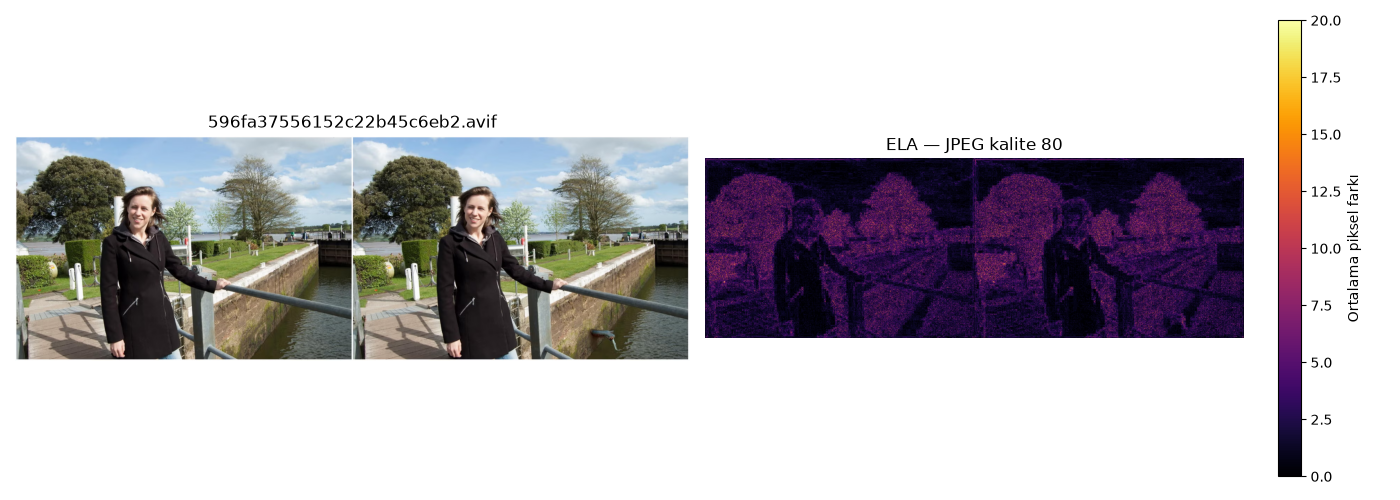

Dosya: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\deneme\596fa37556152c22b45c6eb2.avif
Görüntü boyutu: (640, 1920, 3)
Ortalama ELA farkı: 2.425
Kaydedilen sonuç: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\outputs\deneme_596fa37556152c22b45c6eb2_ela.png


In [43]:
# 1. görsel: 596fa37556152c22b45c6eb2.avif
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Hem proje klasöründen hem de bir üst klasörden dosyayı bul.
project_dir = Path.cwd()
if not (project_dir / "deneme").is_dir():
    project_dir = project_dir / "Image_Processing_Project"
if not (project_dir / "deneme").is_dir():
    project_dir = Path('C:\\Users\\irem\\Desktop\\OKUL\\Image Processing\\Image_Processing_Project')

image_path = project_dir / "deneme" / "596fa37556152c22b45c6eb2.avif"
if not image_path.is_file():
    raise FileNotFoundError(f"Görsel bulunamadı: {image_path.resolve()}")

# Türkçe karakter içeren dosya yollarını da destekler.
image = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Görsel okunamadı: {image_path.name}")

# JPEG'e yeniden kaydet, geri oku ve renk farklarını ortala.
quality = 80
saved, jpeg_data = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, quality])
if not saved:
    raise OSError("JPEG dönüşümü başarısız.")
recompressed = cv2.imdecode(jpeg_data, cv2.IMREAD_COLOR)
ela = cv2.absdiff(image, recompressed).mean(axis=2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(image_path.name)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar(label="Ortalama piksel farkı")
plt.title(f"ELA — JPEG kalite {quality}")
plt.axis("off")

output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)
result_path = output_dir / f"deneme_{image_path.stem}_ela.png"
plt.tight_layout()
plt.savefig(result_path)
plt.show()

print("Dosya:", image_path.resolve())
print("Görüntü boyutu:", image.shape)
print("Ortalama ELA farkı:", round(float(ela.mean()), 3))
print("Kaydedilen sonuç:", result_path.resolve())


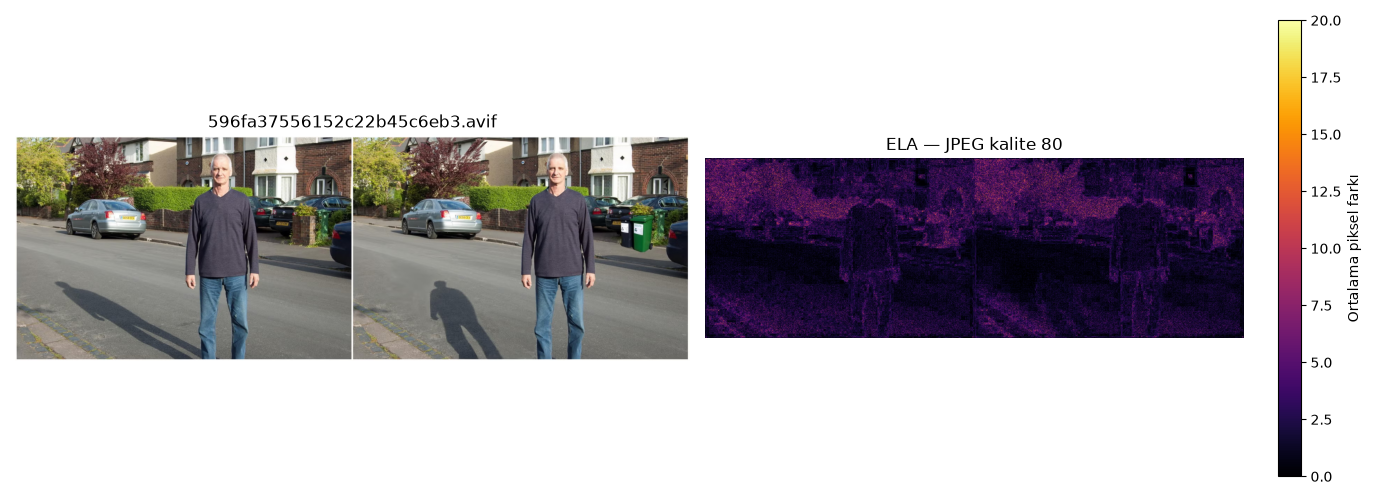

Dosya: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\deneme\596fa37556152c22b45c6eb3.avif
Görüntü boyutu: (641, 1920, 3)
Ortalama ELA farkı: 2.128
Kaydedilen sonuç: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\outputs\deneme_596fa37556152c22b45c6eb3_ela.png


In [44]:
# 2. görsel: 596fa37556152c22b45c6eb3.avif
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Hem proje klasöründen hem de bir üst klasörden dosyayı bul.
project_dir = Path.cwd()
if not (project_dir / "deneme").is_dir():
    project_dir = project_dir / "Image_Processing_Project"
if not (project_dir / "deneme").is_dir():
    project_dir = Path('C:\\Users\\irem\\Desktop\\OKUL\\Image Processing\\Image_Processing_Project')

image_path = project_dir / "deneme" / "596fa37556152c22b45c6eb3.avif"
if not image_path.is_file():
    raise FileNotFoundError(f"Görsel bulunamadı: {image_path.resolve()}")

# Türkçe karakter içeren dosya yollarını da destekler.
image = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Görsel okunamadı: {image_path.name}")

# JPEG'e yeniden kaydet, geri oku ve renk farklarını ortala.
quality = 80
saved, jpeg_data = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, quality])
if not saved:
    raise OSError("JPEG dönüşümü başarısız.")
recompressed = cv2.imdecode(jpeg_data, cv2.IMREAD_COLOR)
ela = cv2.absdiff(image, recompressed).mean(axis=2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(image_path.name)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar(label="Ortalama piksel farkı")
plt.title(f"ELA — JPEG kalite {quality}")
plt.axis("off")

output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)
result_path = output_dir / f"deneme_{image_path.stem}_ela.png"
plt.tight_layout()
plt.savefig(result_path)
plt.show()

print("Dosya:", image_path.resolve())
print("Görüntü boyutu:", image.shape)
print("Ortalama ELA farkı:", round(float(ela.mean()), 3))
print("Kaydedilen sonuç:", result_path.resolve())


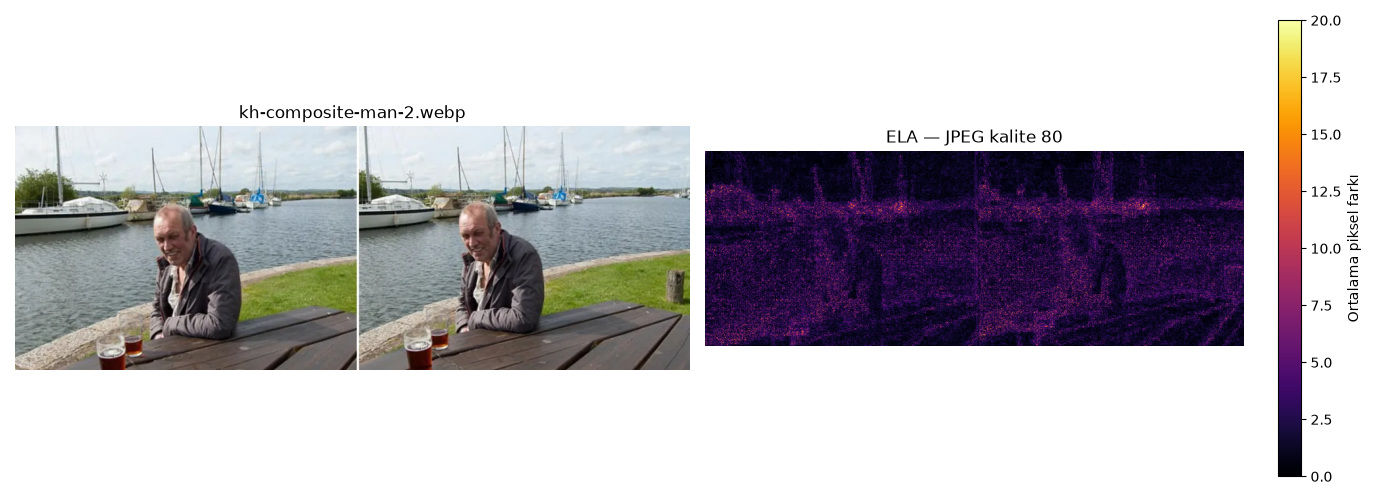

Dosya: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\deneme\kh-composite-man-2.webp
Görüntü boyutu: (370, 1024, 3)
Ortalama ELA farkı: 2.193
Kaydedilen sonuç: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\outputs\deneme_kh-composite-man-2_ela.png


In [45]:
# 3. görsel: kh-composite-man-2.webp
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Hem proje klasöründen hem de bir üst klasörden dosyayı bul.
project_dir = Path.cwd()
if not (project_dir / "deneme").is_dir():
    project_dir = project_dir / "Image_Processing_Project"
if not (project_dir / "deneme").is_dir():
    project_dir = Path('C:\\Users\\irem\\Desktop\\OKUL\\Image Processing\\Image_Processing_Project')

image_path = project_dir / "deneme" / "kh-composite-man-2.webp"
if not image_path.is_file():
    raise FileNotFoundError(f"Görsel bulunamadı: {image_path.resolve()}")

# Türkçe karakter içeren dosya yollarını da destekler.
image = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Görsel okunamadı: {image_path.name}")

# JPEG'e yeniden kaydet, geri oku ve renk farklarını ortala.
quality = 80
saved, jpeg_data = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, quality])
if not saved:
    raise OSError("JPEG dönüşümü başarısız.")
recompressed = cv2.imdecode(jpeg_data, cv2.IMREAD_COLOR)
ela = cv2.absdiff(image, recompressed).mean(axis=2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(image_path.name)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar(label="Ortalama piksel farkı")
plt.title(f"ELA — JPEG kalite {quality}")
plt.axis("off")

output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)
result_path = output_dir / f"deneme_{image_path.stem}_ela.png"
plt.tight_layout()
plt.savefig(result_path)
plt.show()

print("Dosya:", image_path.resolve())
print("Görüntü boyutu:", image.shape)
print("Ortalama ELA farkı:", round(float(ela.mean()), 3))
print("Kaydedilen sonuç:", result_path.resolve())


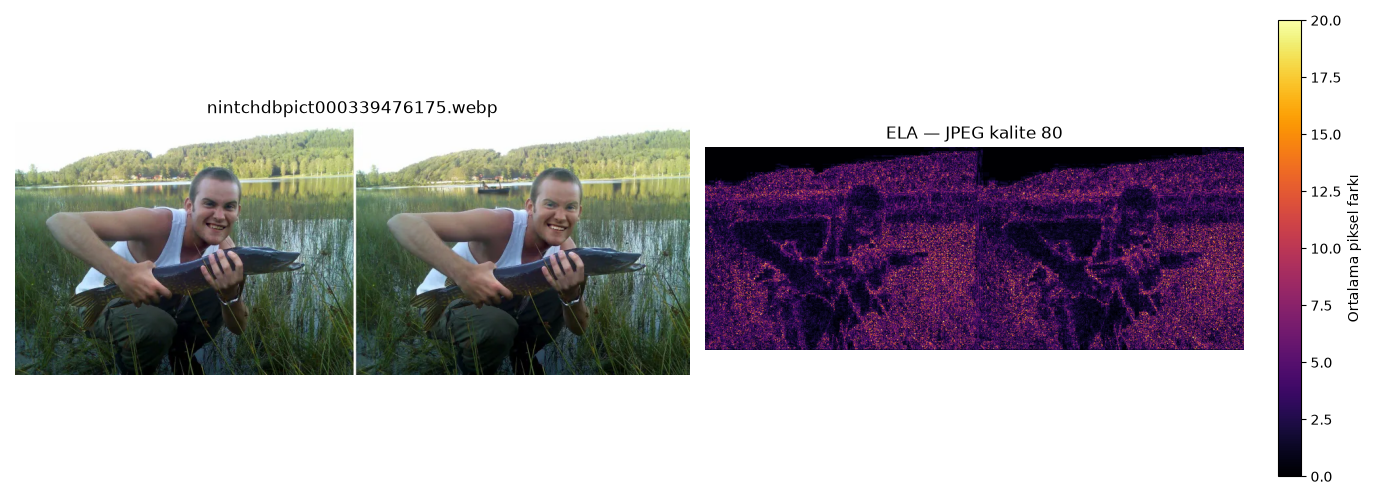

Dosya: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\deneme\nintchdbpict000339476175.webp
Görüntü boyutu: (385, 1024, 3)
Ortalama ELA farkı: 3.393
Kaydedilen sonuç: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\outputs\deneme_nintchdbpict000339476175_ela.png


In [46]:
# 4. görsel: nintchdbpict000339476175.webp
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Hem proje klasöründen hem de bir üst klasörden dosyayı bul.
project_dir = Path.cwd()
if not (project_dir / "deneme").is_dir():
    project_dir = project_dir / "Image_Processing_Project"
if not (project_dir / "deneme").is_dir():
    project_dir = Path('C:\\Users\\irem\\Desktop\\OKUL\\Image Processing\\Image_Processing_Project')

image_path = project_dir / "deneme" / "nintchdbpict000339476175.webp"
if not image_path.is_file():
    raise FileNotFoundError(f"Görsel bulunamadı: {image_path.resolve()}")

# Türkçe karakter içeren dosya yollarını da destekler.
image = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Görsel okunamadı: {image_path.name}")

# JPEG'e yeniden kaydet, geri oku ve renk farklarını ortala.
quality = 80
saved, jpeg_data = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, quality])
if not saved:
    raise OSError("JPEG dönüşümü başarısız.")
recompressed = cv2.imdecode(jpeg_data, cv2.IMREAD_COLOR)
ela = cv2.absdiff(image, recompressed).mean(axis=2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(image_path.name)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar(label="Ortalama piksel farkı")
plt.title(f"ELA — JPEG kalite {quality}")
plt.axis("off")

output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)
result_path = output_dir / f"deneme_{image_path.stem}_ela.png"
plt.tight_layout()
plt.savefig(result_path)
plt.show()

print("Dosya:", image_path.resolve())
print("Görüntü boyutu:", image.shape)
print("Ortalama ELA farkı:", round(float(ela.mean()), 3))
print("Kaydedilen sonuç:", result_path.resolve())


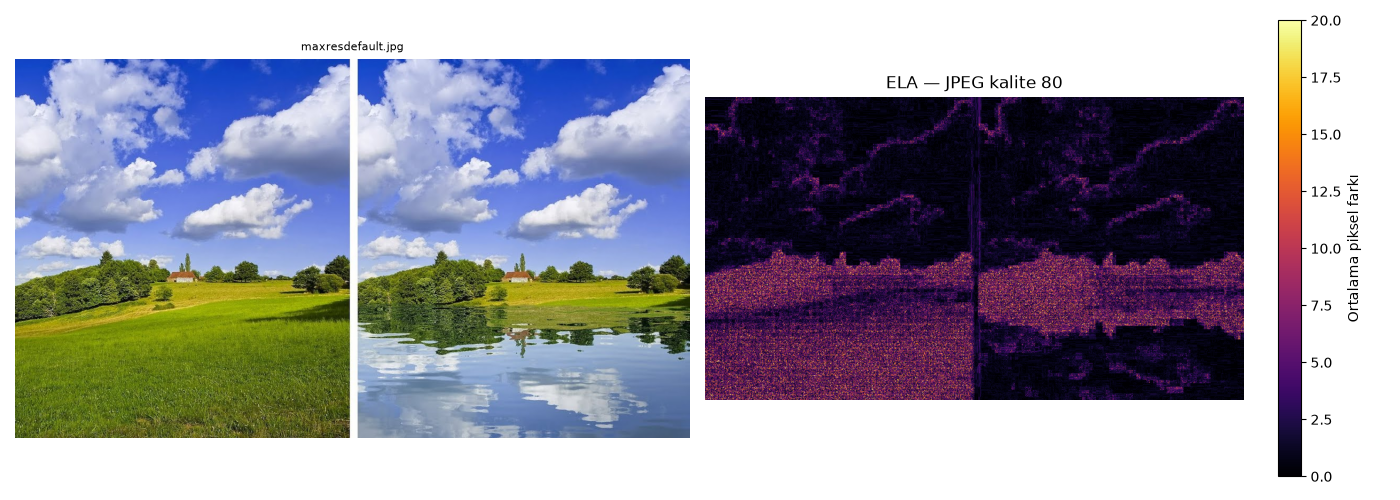

Dosya: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\deneme\maxresdefault.jpg
Görüntü boyutu: (720, 1280, 3)
Ortalama ELA farkı: 2.491
Kaydedilen sonuç: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\outputs\deneme_maxresdefault_ela.png


In [47]:
# 5. görsel: maxresdefault.jpg
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Hem proje klasöründen hem de bir üst klasörden dosyayı bul.
project_dir = Path.cwd()
if not (project_dir / "deneme").is_dir():
    project_dir = project_dir / "Image_Processing_Project"
if not (project_dir / "deneme").is_dir():
    project_dir = Path('C:\\Users\\irem\\Desktop\\OKUL\\Image Processing\\Image_Processing_Project')

image_path = project_dir / "deneme" / "maxresdefault.jpg"
if not image_path.is_file():
    raise FileNotFoundError(f"Görsel bulunamadı: {image_path.resolve()}")

# Türkçe karakter içeren dosya yollarını da destekler.
image = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Görsel okunamadı: {image_path.name}")

# JPEG'e yeniden kaydet, geri oku ve renk farklarını ortala.
quality = 80
saved, jpeg_data = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, quality])
if not saved:
    raise OSError("JPEG dönüşümü başarısız.")
recompressed = cv2.imdecode(jpeg_data, cv2.IMREAD_COLOR)
ela = cv2.absdiff(image, recompressed).mean(axis=2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(image_path.name, fontsize=8)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar(label="Ortalama piksel farkı")
plt.title(f"ELA — JPEG kalite {quality}")
plt.axis("off")

output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)
result_path = output_dir / f"deneme_{image_path.stem}_ela.png"
plt.tight_layout()
plt.savefig(result_path)
plt.show()

print("Dosya:", image_path.resolve())
print("Görüntü boyutu:", image.shape)
print("Ortalama ELA farkı:", round(float(ela.mean()), 3))
print("Kaydedilen sonuç:", result_path.resolve())


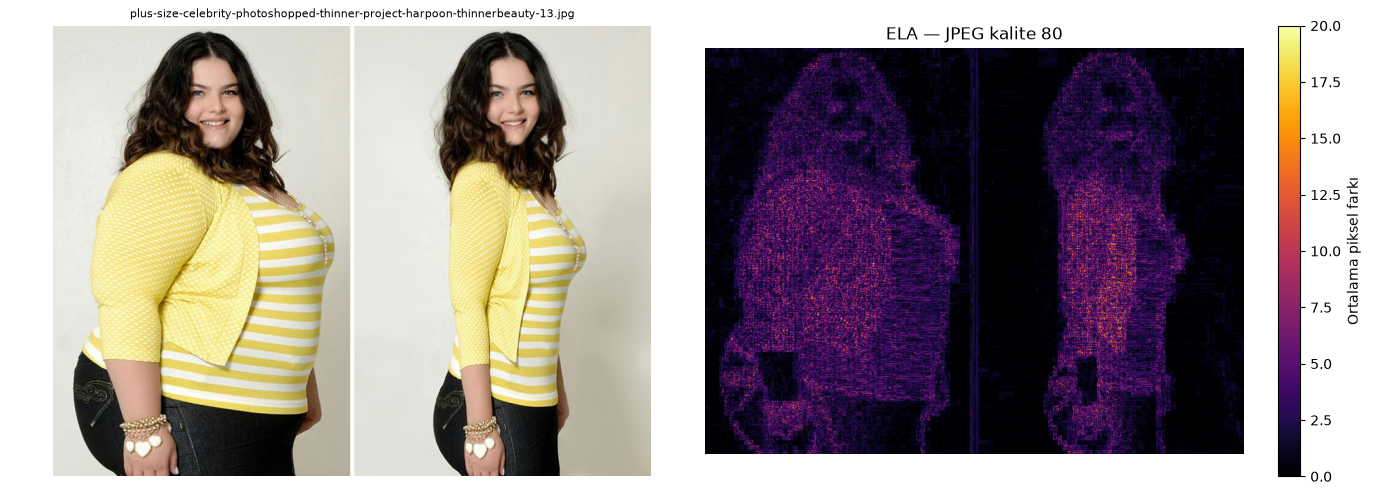

Dosya: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\deneme\plus-size-celebrity-photoshopped-thinner-project-harpoon-thinnerbeauty-13.jpg
Görüntü boyutu: (663, 880, 3)
Ortalama ELA farkı: 1.874
Kaydedilen sonuç: C:\Users\irem\Desktop\OKUL\Image Processing\Image_Processing_Project\outputs\deneme_plus-size-celebrity-photoshopped-thinner-project-harpoon-thinnerbeauty-13_ela.png


In [48]:
# 6. görsel: plus-size-celebrity-photoshopped-thinner-project-harpoon-thinnerbeauty-13.jpg
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Hem proje klasöründen hem de bir üst klasörden dosyayı bul.
project_dir = Path.cwd()
if not (project_dir / "deneme").is_dir():
    project_dir = project_dir / "Image_Processing_Project"
if not (project_dir / "deneme").is_dir():
    project_dir = Path('C:\\Users\\irem\\Desktop\\OKUL\\Image Processing\\Image_Processing_Project')

image_path = project_dir / "deneme" / "plus-size-celebrity-photoshopped-thinner-project-harpoon-thinnerbeauty-13.jpg"
if not image_path.is_file():
    raise FileNotFoundError(f"Görsel bulunamadı: {image_path.resolve()}")

# Türkçe karakter içeren dosya yollarını da destekler.
image = cv2.imdecode(np.fromfile(image_path, dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Görsel okunamadı: {image_path.name}")

# JPEG'e yeniden kaydet, geri oku ve renk farklarını ortala.
quality = 80
saved, jpeg_data = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, quality])
if not saved:
    raise OSError("JPEG dönüşümü başarısız.")
recompressed = cv2.imdecode(jpeg_data, cv2.IMREAD_COLOR)
ela = cv2.absdiff(image, recompressed).mean(axis=2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(image_path.name, fontsize=8)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar(label="Ortalama piksel farkı")
plt.title(f"ELA — JPEG kalite {quality}")
plt.axis("off")

output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)
result_path = output_dir / f"deneme_{image_path.stem}_ela.png"
plt.tight_layout()
plt.savefig(result_path)
plt.show()

print("Dosya:", image_path.resolve())
print("Görüntü boyutu:", image.shape)
print("Ortalama ELA farkı:", round(float(ela.mean()), 3))
print("Kaydedilen sonuç:", result_path.resolve())
